In [14]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

(X_train, y_train), (X_test, y_test) = (
    keras.datasets.fashion_mnist.load_data()
)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [15]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

In [16]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


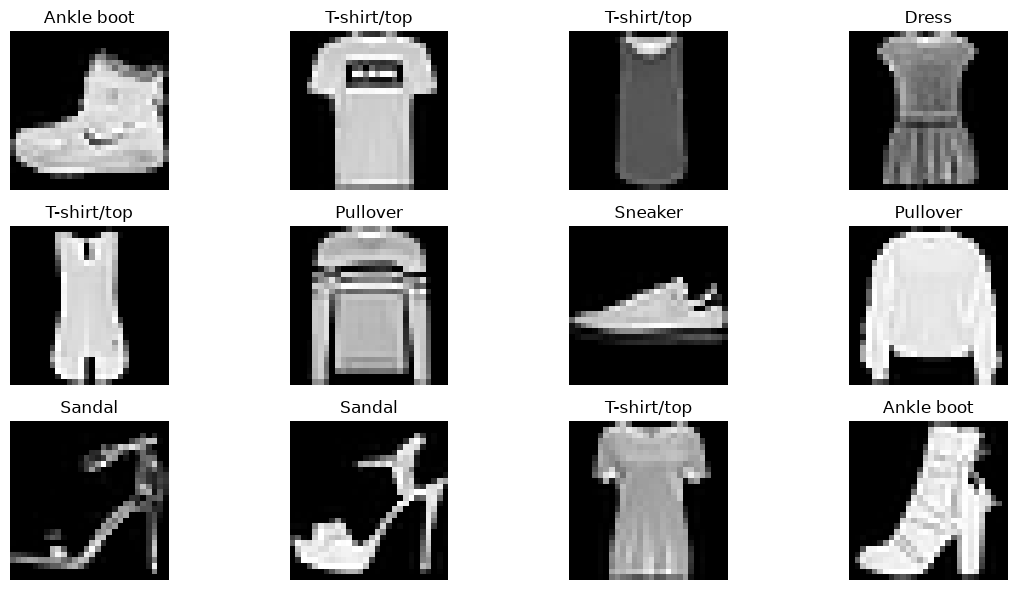

In [17]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # First convolution block
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolution block
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification block
    layers.Flatten(),

    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),

    layers.Dense(10, activation="softmax")
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [20]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.8039 - loss: 0.5360 - val_accuracy: 0.8659 - val_loss: 0.3780
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.8677 - loss: 0.3650 - val_accuracy: 0.8739 - val_loss: 0.3378
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.8825 - loss: 0.3167 - val_accuracy: 0.8901 - val_loss: 0.2993
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.8953 - loss: 0.2852 - val_accuracy: 0.8997 - val_loss: 0.2739
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.9041 - loss: 0.2607 - val_accuracy: 0.8972 - val_loss: 0.2764
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9112 - loss: 0.2414 - val_accuracy: 0.9086 - val_loss: 0.2503
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.9155 - loss: 0.2265 - val_accuracy: 0.9082 - val_loss: 0.2500
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 22s 30ms/step - accuracy: 0.9219 - loss: 0.2091 - 

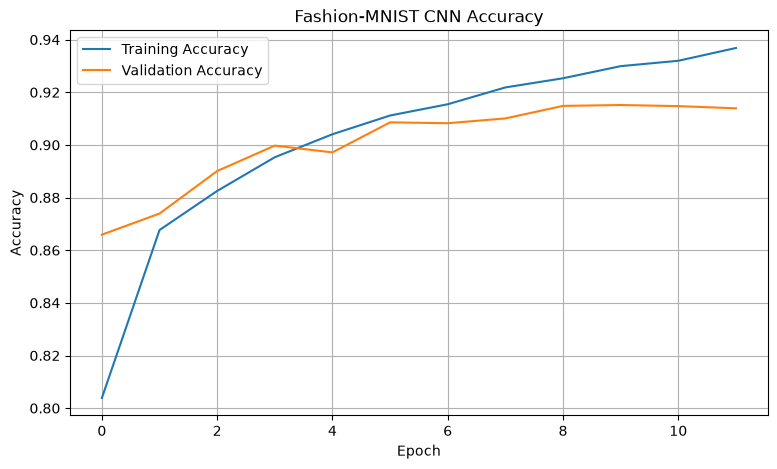

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fashion-MNIST CNN Accuracy")
plt.legend()
plt.grid(True)
plt.show()

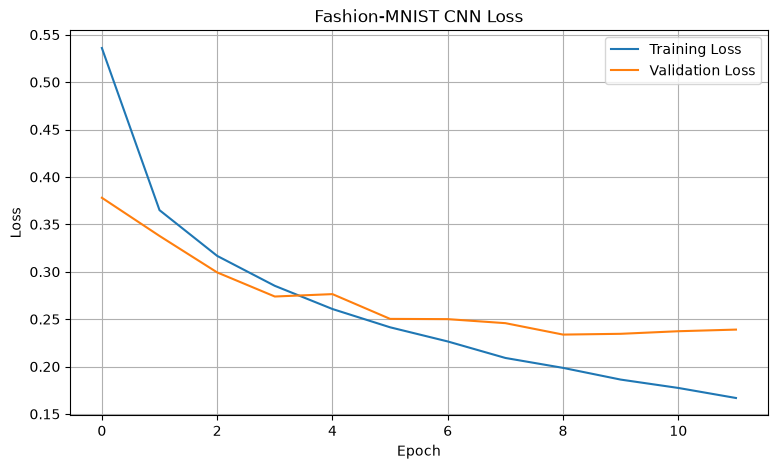

In [22]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fashion-MNIST CNN Loss")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
test_loss, test_accuracy = cnn_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.24890710413455963
Test Accuracy: 0.9085000157356262


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


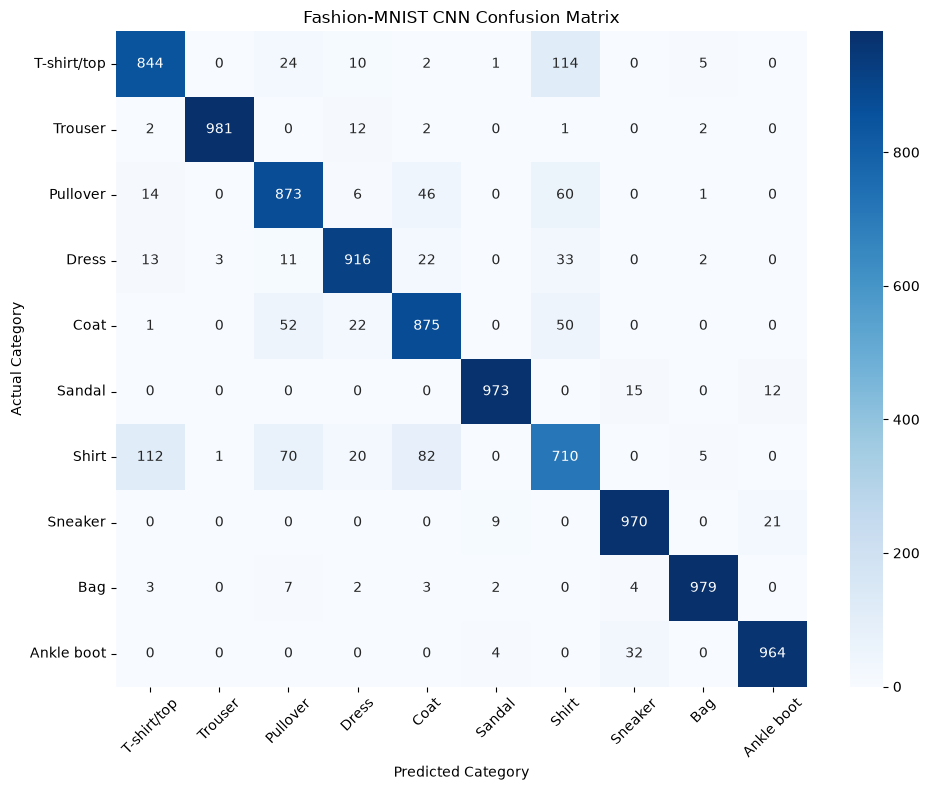

In [24]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

predictions = cnn_model.predict(X_test)

y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Fashion-MNIST CNN Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.84      0.85      1000
     Trouser       1.00      0.98      0.99      1000
    Pullover       0.84      0.87      0.86      1000
       Dress       0.93      0.92      0.92      1000
        Coat       0.85      0.88      0.86      1000
      Sandal       0.98      0.97      0.98      1000
       Shirt       0.73      0.71      0.72      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



In [26]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\SUBHOJIT\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1


In [27]:
pip install kagglehub

^C
Note: you may need to restart the kernel to use updated packages.


In [37]:
from pathlib import Path

DATASET_PATH = Path(path)

csv_files = list(DATASET_PATH.rglob("styles.csv"))

if not csv_files:
    raise FileNotFoundError("styles.csv not found in downloaded dataset")

STYLES_PATH = csv_files[0]
IMAGE_DIR = STYLES_PATH.parent / "images"

print("Dataset directory:", DATASET_PATH)
print("Metadata file:", STYLES_PATH)
print("Image directory:", IMAGE_DIR)

print("Images directory exists:", IMAGE_DIR.exists())

Dataset directory: C:\Users\SUBHOJIT\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1
Metadata file: C:\Users\SUBHOJIT\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1\styles.csv
Image directory: C:\Users\SUBHOJIT\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1\images
Images directory exists: True


In [38]:
import pandas as pd

styles_df = pd.read_csv(
    STYLES_PATH,
    on_bad_lines="skip"
)

print("Dataset shape:", styles_df.shape)

styles_df.head()

Dataset shape: (44424, 10)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [39]:
print("Total image files:", len(list(IMAGE_DIR.glob("*.jpg"))))

print("Sample image files:")

for image_file in list(IMAGE_DIR.glob("*.jpg"))[:5]:
    print(image_file.name)

Total image files: 44441
Sample image files:
10000.jpg
10001.jpg
10002.jpg
10003.jpg
10004.jpg


In [40]:
styles_df["image_path"] = styles_df["id"].apply(
    lambda x: IMAGE_DIR / f"{int(x)}.jpg"
)

styles_df = styles_df.dropna(
    subset=["articleType"]
).copy()

styles_df = styles_df[
    styles_df["image_path"].apply(lambda x: x.exists())
].copy()

print("Available product images:", len(styles_df))

Available product images: 44419


In [41]:
category_counts = styles_df["articleType"].value_counts()

print("Total categories:", len(category_counts))

category_counts.head(20)

Total categories: 142


articleType
Tshirts                  7066
Shirts                   3215
Casual Shoes             2845
Watches                  2542
Sports Shoes             2036
Kurtas                   1844
Tops                     1762
Handbags                 1759
Heels                    1323
Sunglasses               1073
Wallets                   936
Flip Flops                914
Sandals                   897
Briefs                    849
Belts                     813
Backpacks                 724
Socks                     686
Formal Shoes              637
Perfume and Body Mist     613
Jeans                     608
Name: count, dtype: int64

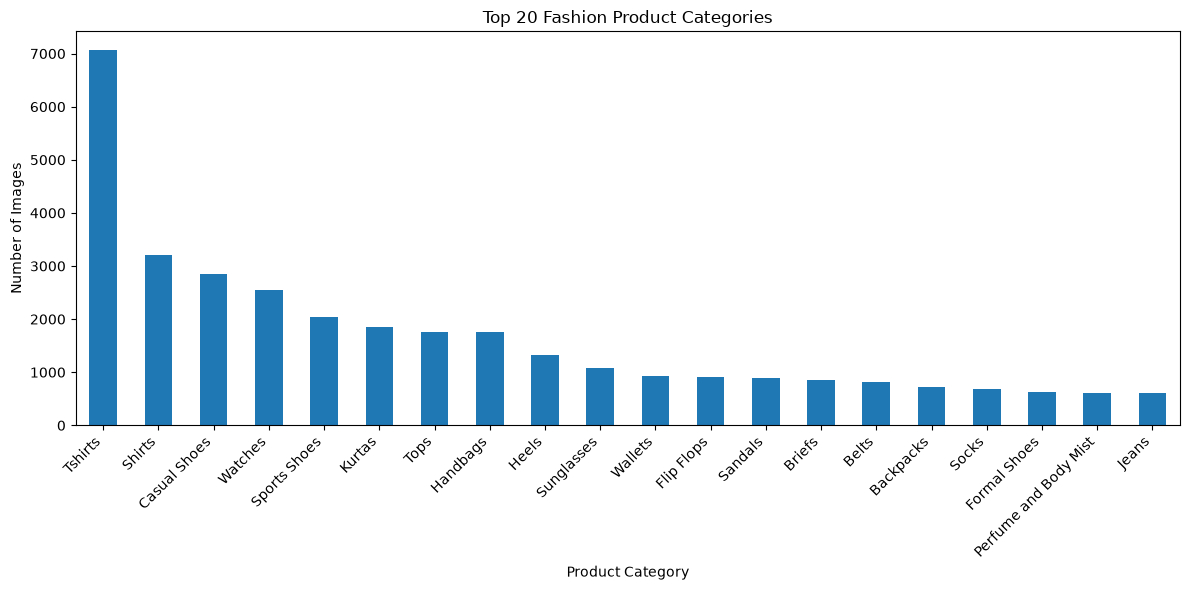

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

category_counts.head(20).plot(kind="bar")

plt.title("Top 20 Fashion Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [43]:
MIN_SAMPLES = 100

valid_categories = category_counts[
    category_counts >= MIN_SAMPLES
].index

product_df = styles_df[
    styles_df["articleType"].isin(valid_categories)
].copy()

print("Total product images:", len(product_df))
print("Selected categories:", product_df["articleType"].nunique())

Total product images: 42150
Selected categories: 54


In [44]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

product_df["label"] = label_encoder.fit_transform(
    product_df["masterCategory"]
)

class_names = label_encoder.classes_

print("Number of classes:", len(class_names))
print("\nCategory mapping:")

for index, category in enumerate(class_names):
    print(index, ":", category)

Number of classes: 5

Category mapping:
0 : Accessories
1 : Apparel
2 : Footwear
3 : Free Items
4 : Personal Care


In [45]:

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    product_df,
    test_size=0.30,
    random_state=42,
    stratify=product_df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

Training records: 29505
Validation records: 6322
Testing records: 6323


In [46]:
print("Training distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["label"].value_counts().sort_index())

print("\nTesting distribution:")
print(test_df["label"].value_counts().sort_index())

Training distribution:
label
0     7316
1    14480
2     6407
3        8
4     1294
Name: count, dtype: int64

Validation distribution:
label
0    1567
1    3103
2    1372
3       2
4     278
Name: count, dtype: int64

Testing distribution:
label
0    1568
1    3103
2    1373
3       2
4     277
Name: count, dtype: int64


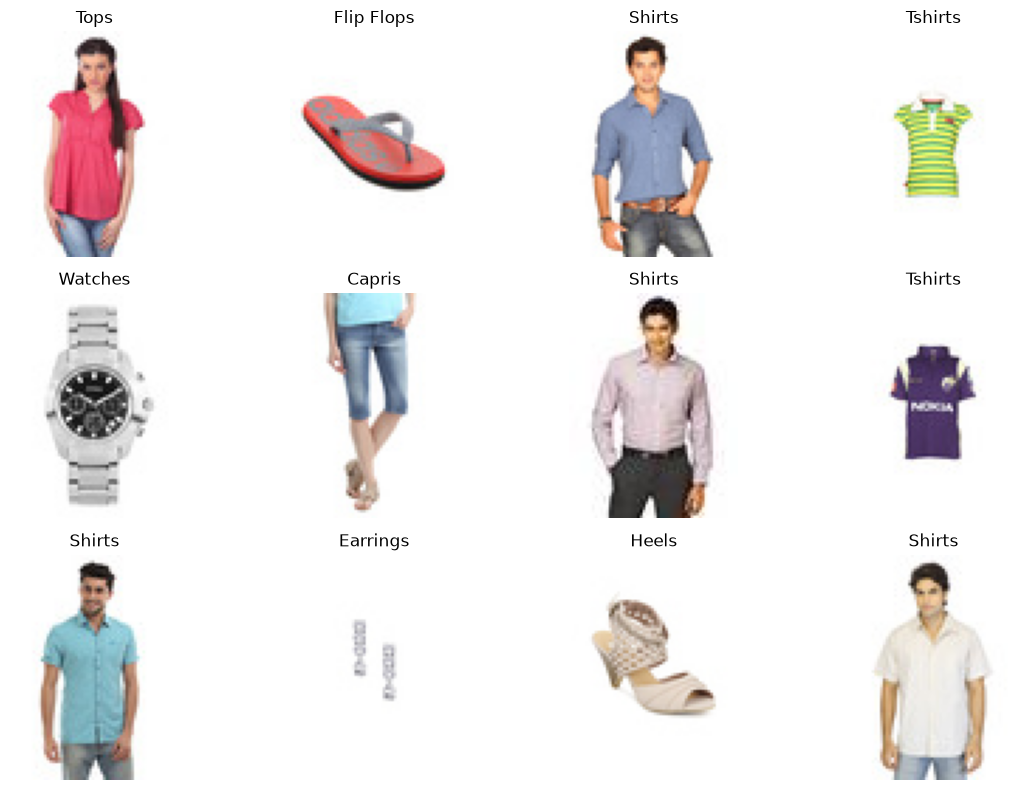

In [47]:
from PIL import Image

plt.figure(figsize=(12, 8))

sample_df = train_df.sample(
    n=12,
    random_state=42
).reset_index(drop=True)

for i, row in sample_df.iterrows():
    image = Image.open(row["image_path"]).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(row["articleType"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [48]:
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

NUM_CLASSES = len(class_names)

print("Image size:", IMG_HEIGHT, IMG_WIDTH)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: 128 128
Batch size: 32
Number of classes: 5


In [49]:
def load_and_preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [50]:
def create_image_dataset(dataframe, training=False):

    image_paths = dataframe["image_path"].astype(str).values
    labels = dataframe["label"].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 5000),
            seed=42
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.map(
            lambda image, label: (
                tf.image.random_flip_left_right(image),
                label
            ),
            num_parallel_calls=AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

In [51]:
train_ds = create_image_dataset(
    train_df,
    training=True
)

val_ds = create_image_dataset(
    val_df,
    training=False
)

test_ds = create_image_dataset(
    test_df,
    training=False
)

In [52]:
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


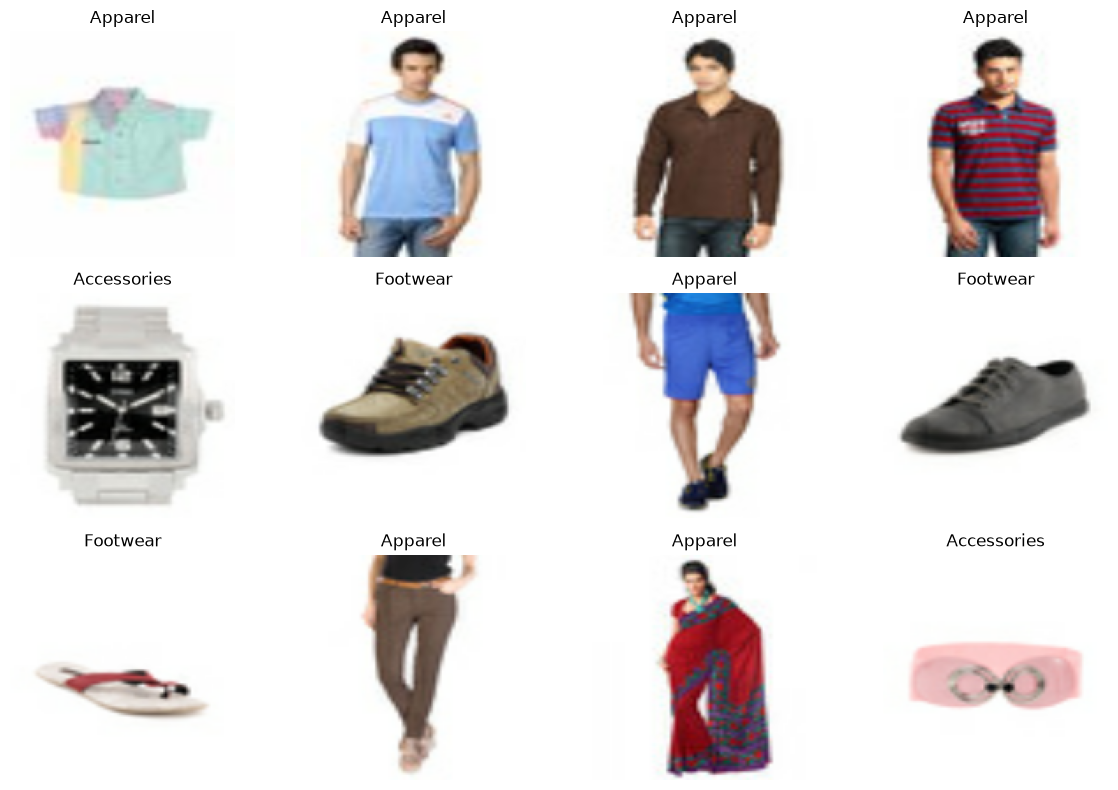

In [53]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):

    for i in range(min(12, len(images))):

        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy())

        plt.title(class_names[labels[i].numpy()])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [54]:
cnn_model = keras.Sequential([

    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification block
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled successfully.")

In [62]:
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

print("Project directory:", BASE_DIR)

Project directory: d:\RetailMind


In [ ]:
MODEL_DIR = BASE_DIR / "models"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Model directory:", MODEL_DIR)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "best_product_cnn.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [ ]:
# Train the model on the Fashion Product Images dataset
EPOCHS = 15

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

In [ ]:
import numpy as np

# Actual labels
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

# Predicted probabilities
y_prob = cnn_model.predict(test_ds)

# Convert probabilities into predicted class indices
y_pred = np.argmax(y_prob, axis=1)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision (weighted):", precision_score(y_true, y_pred, average="weighted", zero_division=0))
print("Recall (weighted):", recall_score(y_true, y_pred, average="weighted", zero_division=0))
print("F1 Score (weighted):", f1_score(y_true, y_pred, average="weighted", zero_division=0))

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Fashion Product CNN - Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
def predict_product_image(image_path):
    image = tf.io.read_file(str(image_path))

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    image = tf.cast(image, tf.float32) / 255.0

    # Add batch dimension
    image = tf.expand_dims(image, axis=0)

    # Predict probabilities
    probabilities = cnn_model.predict(image, verbose=0)[0]

    predicted_index = int(np.argmax(probabilities))

    predicted_category = class_names[predicted_index]

    confidence = float(probabilities[predicted_index]) * 100

    return predicted_category, confidence, probabilities

In [ ]:
sample_image_path = test_df.iloc[0]["image_path"]

predicted_category, confidence, probabilities = predict_product_image(
    sample_image_path
)

print("Predicted category:", predicted_category)
print(f"Confidence: {confidence:.2f}%")

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open(sample_image_path)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")

plt.title(
    f"Prediction: {predicted_category}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

In [ ]:
top_3_indices = np.argsort(probabilities)[-3:][::-1]

for index in top_3_indices:
    print(
        f"{class_names[index]}: "
        f"{probabilities[index] * 100:.2f}%"
    )

In [ ]:
import json

class_mapping = {
    int(index): str(category)
    for index, category in enumerate(class_names)
}

mapping_path = MODEL_DIR / "product_class_mapping.json"

with open(mapping_path, "w") as file:
    json.dump(class_mapping, file, indent=4)

print("Class mapping saved:", mapping_path)

In [ ]:
FINAL_MODEL_PATH = MODEL_DIR / "fashion_product_cnn.keras"

cnn_model.save(FINAL_MODEL_PATH)

print("Model saved at:", FINAL_MODEL_PATH)

In [ ]:
image_config = {
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "channels": 3,
    "normalization": "pixel_values_divided_by_255",
    "num_classes": int(NUM_CLASSES)
}

config_path = MODEL_DIR / "product_image_config.json"

with open(config_path, "w") as file:
    json.dump(image_config, file, indent=4)

print("Image configuration saved:", config_path)

In [ ]:

loaded_model = keras.models.load_model(
    MODEL_DIR / "fashion_product_cnn.keras"
)

print("Saved model loaded successfully!")

print("Input shape:", loaded_model.input_shape)
print("Output shape:", loaded_model.output_shape)

Day 7


In [28]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from tensorflow.keras import layers, models
from tensorflow import keras

import numpy as np
import matplotlib.pyplot as plt
import json

In [29]:
IMG_HEIGHT = 128
IMG_WIDTH = 128

NUM_CLASSES = len(class_names)

print("Image dimensions:", IMG_HEIGHT, IMG_WIDTH)
print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)

Image dimensions: 128 128
Number of classes: 10
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [30]:
def preprocess_vgg16(image, label):

    # Convert normalized pixel values back to 0-255
    image = image * 255.0

    # Apply VGG16 ImageNet preprocessing
    image = preprocess_input(image)

    return image, label

In [55]:
train_vgg_ds = train_ds.map(
    preprocess_vgg16,
    num_parallel_calls=AUTOTUNE
)

val_vgg_ds = val_ds.map(
    preprocess_vgg16,
    num_parallel_calls=AUTOTUNE
)

test_vgg_ds = test_ds.map(
    preprocess_vgg16,
    num_parallel_calls=AUTOTUNE
)

In [56]:
for images, labels in train_vgg_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:",
          tf.reduce_min(images).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(images).numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: -123.68
Maximum pixel value: 151.061


In [57]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

print("VGG16 loaded successfully!")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step
VGG16 loaded successfully!


In [58]:
base_model.trainable = False

print("Total VGG16 layers:", len(base_model.layers))

print("Trainable layers:",
      sum(layer.trainable for layer in base_model.layers))

Total VGG16 layers: 19
Trainable layers: 0


In [59]:
inputs = keras.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

# Extract features using pretrained VGG16
x = base_model(inputs, training=False)

# Convert feature maps into a vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.4)(x)

# Custom classification layer
x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

# Final output layer
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

vgg_model = keras.Model(
    inputs=inputs,
    outputs=outputs
)

vgg_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 132,613 (518.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [60]:
vgg_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("VGG16 model compiled successfully!")

VGG16 model compiled successfully!


In [63]:
MODEL_DIR = BASE_DIR / "models"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

frozen_callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "best_vgg16_frozen.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [64]:
FROZEN_EPOCHS = 10

frozen_history = vgg_model.fit(
    train_vgg_ds,

    validation_data=val_vgg_ds,

    epochs=FROZEN_EPOCHS,

    callbacks=frozen_callbacks,

    verbose=1
)

Epoch 1/10


d:\RetailMind\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


923/923 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9768 - loss: 0.0983
Epoch 1: val_loss improved from None to 0.06701, saving model to d:\RetailMind\models\best_vgg16_frozen.keras

Epoch 1: finished saving model to d:\RetailMind\models\best_vgg16_frozen.keras
923/923 ━━━━━━━━━━━━━━━━━━━━ 1121s 1s/step - accuracy: 0.9768 - loss: 0.0983 - val_accuracy: 0.9848 - val_loss: 0.0670
Epoch 2/10
923/923 ━━━━━━━━━━━━━━━━━━━━ 0s 712ms/step - accuracy: 0.9906 - loss: 0.0327
Epoch 2: val_loss improved from 0.06701 to 0.05361, saving model to d:\RetailMind\models\best_vgg16_frozen.keras

Epoch 2: finished saving model to d:\RetailMind\models\best_vgg16_frozen.keras
923/923 ━━━━━━━━━━━━━━━━━━━━ 798s 864ms/step - accuracy: 0.9906 - loss: 0.0327 - val_accuracy: 0.9883 - val_loss: 0.0536
Epoch 3/10
923/923 ━━━━━━━━━━━━━━━━━━━━ 0s 701ms/step - accuracy: 0.9940 - loss: 0.0235
Epoch 3: val_loss did not improve from 0.05361
923/923 ━━━━━━━━━━━━━━━━━━━━ 790s 856ms/step - accuracy: 0.9940 - loss: 0.0235 -

In [ ]:
base_model.trainable = True

# Freeze all layers initially
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze the last four layers
base_model.trainable = True

for layer in base_model.layers[:-8]:
    layer.trainable = False

for layer in base_model.layers[-8:]:
    layer.trainable = True

print("Trainable VGG16 layers:")

for layer in base_model.layers:

    if layer.trainable:
        print(layer.name)

Trainable VGG16 layers:
block4_conv1
block4_conv2
block4_conv3
block4_pool
block5_conv1
block5_conv2
block5_conv3
block5_pool


In [66]:
vgg_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("VGG16 fine-tuning compilation completed!")

VGG16 fine-tuning compilation completed!


In [67]:
fine_tune_callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "best_vgg16_finetuned.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [68]:
FINE_TUNE_EPOCHS = 5

fine_tune_history = vgg_model.fit(

    train_vgg_ds,

    validation_data=val_vgg_ds,

    epochs=FINE_TUNE_EPOCHS,

    callbacks=fine_tune_callbacks,

    verbose=1
)

Epoch 1/5
923/923 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9944 - loss: 0.0223
Epoch 1: val_loss improved from None to 0.03773, saving model to d:\RetailMind\models\best_vgg16_finetuned.keras

Epoch 1: finished saving model to d:\RetailMind\models\best_vgg16_finetuned.keras
923/923 ━━━━━━━━━━━━━━━━━━━━ 1332s 1s/step - accuracy: 0.9944 - loss: 0.0223 - val_accuracy: 0.9941 - val_loss: 0.0377
Epoch 2/5
923/923 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9976 - loss: 0.0085
Epoch 2: val_loss did not improve from 0.03773
923/923 ━━━━━━━━━━━━━━━━━━━━ 1414s 2s/step - accuracy: 0.9976 - loss: 0.0085 - val_accuracy: 0.9940 - val_loss: 0.0426
Epoch 3/5
923/923 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9980 - loss: 0.0072
Epoch 3: val_loss improved from 0.03773 to 0.03327, saving model to d:\RetailMind\models\best_vgg16_finetuned.keras

Epoch 3: finished saving model to d:\RetailMind\models\best_vgg16_finetuned.keras
923/923 ━━━━━━━━━━━━━━━━━━━━ 1612s 2s/step - accuracy: 0.9980 - loss

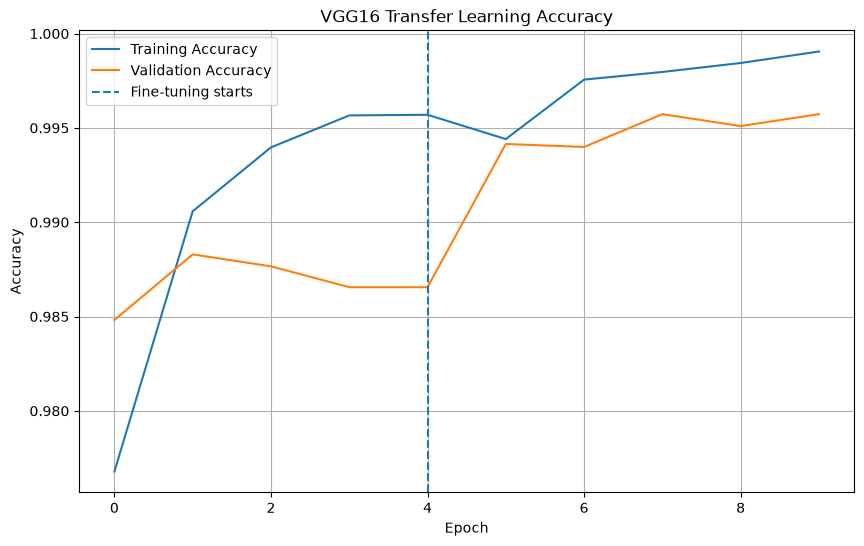

In [69]:
frozen_acc = frozen_history.history["accuracy"]
fine_tune_acc = fine_tune_history.history["accuracy"]

frozen_val_acc = frozen_history.history["val_accuracy"]
fine_tune_val_acc = fine_tune_history.history["val_accuracy"]

plt.figure(figsize=(10, 6))

plt.plot(
    frozen_acc + fine_tune_acc,
    label="Training Accuracy"
)

plt.plot(
    frozen_val_acc + fine_tune_val_acc,
    label="Validation Accuracy"
)

plt.axvline(
    x=len(frozen_acc) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("VGG16 Transfer Learning Accuracy")

plt.legend()
plt.grid(True)
plt.show()

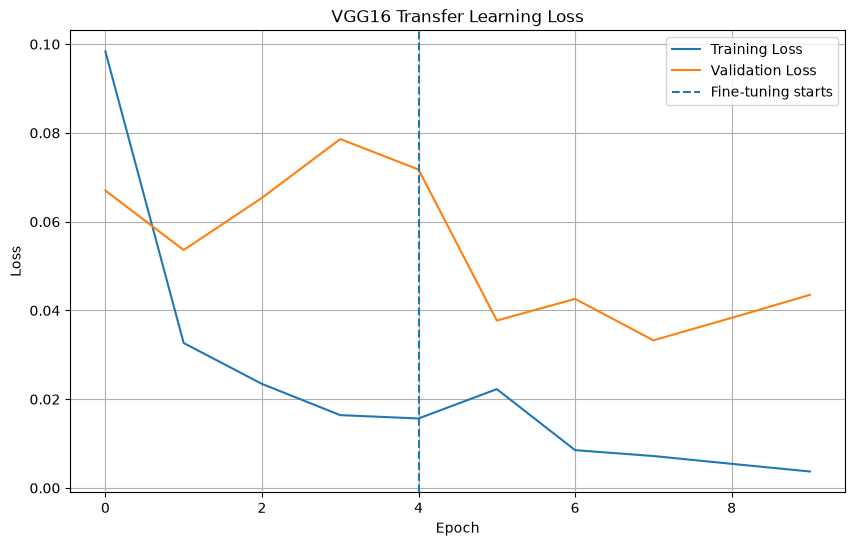

In [70]:
frozen_loss = frozen_history.history["loss"]
fine_tune_loss = fine_tune_history.history["loss"]

frozen_val_loss = frozen_history.history["val_loss"]
fine_tune_val_loss = fine_tune_history.history["val_loss"]

plt.figure(figsize=(10, 6))

plt.plot(
    frozen_loss + fine_tune_loss,
    label="Training Loss"
)

plt.plot(
    frozen_val_loss + fine_tune_val_loss,
    label="Validation Loss"
)

plt.axvline(
    x=len(frozen_loss) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("VGG16 Transfer Learning Loss")

plt.legend()
plt.grid(True)
plt.show()

In [71]:
vgg_test_loss, vgg_test_accuracy = vgg_model.evaluate(
    test_vgg_ds,
    verbose=1
)

print("VGG16 Test Loss:", vgg_test_loss)

print(
    "VGG16 Test Accuracy:",
    f"{vgg_test_accuracy * 100:.2f}%"
)

198/198 ━━━━━━━━━━━━━━━━━━━━ 193s 968ms/step - accuracy: 0.9960 - loss: 0.0232
VGG16 Test Loss: 0.023171408101916313
VGG16 Test Accuracy: 99.60%


In [72]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_vgg_ds
])

y_prob = vgg_model.predict(test_vgg_ds)

y_pred = np.argmax(y_prob, axis=1)

print("Accuracy:",
      accuracy_score(y_true, y_pred))

print("Precision:",
      precision_score(
          y_true, y_pred,
          average="weighted",
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_true, y_pred,
          average="weighted",
          zero_division=0
      ))

print("F1 Score:",
      f1_score(
          y_true, y_pred,
          average="weighted",
          zero_division=0
      ))

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

198/198 ━━━━━━━━━━━━━━━━━━━━ 212s 1s/step
Accuracy: 0.9960461806104697
Precision: 0.9957353984772551
Recall: 0.9960461806104697
F1 Score: 0.9958896263754216

Classification Report:

               precision    recall  f1-score   support

  Accessories       0.99      0.99      0.99      1568
      Apparel       1.00      1.00      1.00      3103
     Footwear       1.00      1.00      1.00      1373
   Free Items       0.00      0.00      0.00         2
Personal Care       0.99      1.00      0.99       277

     accuracy                           1.00      6323
    macro avg       0.80      0.80      0.80      6323
 weighted avg       1.00      1.00      1.00      6323



In [73]:
DAY6_MODEL_PATH = MODEL_DIR / "fashion_product_cnn.keras"

if not DAY6_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Day 6 model not found: {DAY6_MODEL_PATH}"
    )

day6_model = keras.models.load_model(
    DAY6_MODEL_PATH
)

print("Day 6 CNN loaded successfully!")

Day 6 CNN loaded successfully!


In [74]:
day6_loss, day6_accuracy = day6_model.evaluate(
    test_ds,
    verbose=1
)

print(
    "Day 6 CNN Test Accuracy:",
    f"{day6_accuracy * 100:.2f}%"
)

print(
    "Day 7 VGG16 Test Accuracy:",
    f"{vgg_test_accuracy * 100:.2f}%"
)

198/198 ━━━━━━━━━━━━━━━━━━━━ 16s 70ms/step - accuracy: 0.9745 - loss: 0.0863
Day 6 CNN Test Accuracy: 97.45%
Day 7 VGG16 Test Accuracy: 99.60%


In [75]:


comparison_df = pd.DataFrame({

    "Model": [
        "Day 6 Custom CNN",
        "Day 7 VGG16"
    ],

    "Test Accuracy": [
        day6_accuracy * 100,
        vgg_test_accuracy * 100
    ],

    "Test Loss": [
        day6_loss,
        vgg_test_loss
    ]
})

comparison_df

,Model,Test Accuracy,Test Loss
0,Day 6 Custom CNN,97.453743,0.086297
1,Day 7 VGG16,99.604619,0.023171


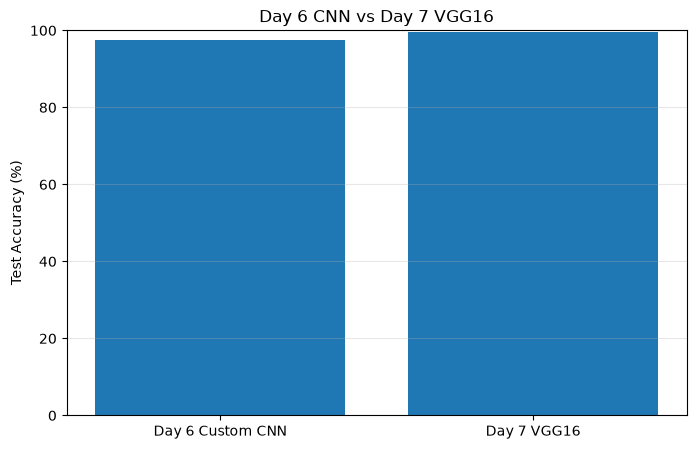

In [76]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy"]
)

plt.ylabel("Test Accuracy (%)")

plt.title(
    "Day 6 CNN vs Day 7 VGG16"
)

plt.ylim(0, 100)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [81]:
accuracy_difference = (
    vgg_test_accuracy - day6_accuracy
) * 100

print(
    f"Accuracy difference: {accuracy_difference:.2f} percentage points"
)

if accuracy_difference > 0:

    print("VGG16 performed better than the Day 6 CNN.")

elif accuracy_difference < 0:

    print("Day 6 CNN performed better than VGG16.")

else:

    print("Both models achieved the same accuracy.")

Accuracy difference: 2.15 percentage points
VGG16 performed better than the Day 6 CNN.


In [82]:
VGG_MODEL_PATH = MODEL_DIR / "fashion_product_vgg16.keras"

vgg_model.save(VGG_MODEL_PATH)

print("VGG16 model saved:", VGG_MODEL_PATH)

VGG16 model saved: d:\RetailMind\models\fashion_product_vgg16.keras


In [83]:
class_mapping = {
    int(index): str(category)
    for index, category in enumerate(class_names)
}

mapping_path = (
    MODEL_DIR / "vgg16_class_mapping.json"
)

with open(mapping_path, "w") as file:

    json.dump(
        class_mapping,
        file,
        indent=4
    )

print("Class mapping saved:", mapping_path)

Class mapping saved: d:\RetailMind\models\vgg16_class_mapping.json


In [84]:
day7_results = {

    "model": "VGG16 Transfer Learning",

    "image_height": IMG_HEIGHT,

    "image_width": IMG_WIDTH,

    "num_classes": NUM_CLASSES,

    "day6_cnn_accuracy": float(day6_accuracy),

    "day7_vgg16_accuracy": float(vgg_test_accuracy),

    "day7_vgg16_loss": float(vgg_test_loss),

    "accuracy_difference_percentage_points": float(accuracy_difference)
    
}

results_path = MODEL_DIR / "day7_vgg16_results.json"

with open(results_path, "w") as file:

    json.dump(
        day7_results,
        file,
        indent=4
    )

print("Day 7 results saved:", results_path)

Day 7 results saved: d:\RetailMind\models\day7_vgg16_results.json


In [85]:
def predict_product_vgg16(image_path):

    image = tf.io.read_file(str(image_path))

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    image = image * 255.0

    image = preprocess_input(image)

    image = tf.expand_dims(image, axis=0)

    probabilities = vgg_model.predict(
        image,
        verbose=0
    )[0]

    predicted_index = int(
        np.argmax(probabilities)
    )

    predicted_category = class_names[predicted_index]

    confidence = float(
        probabilities[predicted_index]
    ) * 100

    return predicted_category, confidence, probabilities

In [86]:
sample_image_path = test_df.iloc[0]["image_path"]

predicted_category, confidence, probabilities = (
    predict_product_vgg16(sample_image_path)
)

print("Predicted Category:", predicted_category)

print(f"Confidence: {confidence:.2f}%")

Predicted Category: Accessories
Confidence: 100.00%


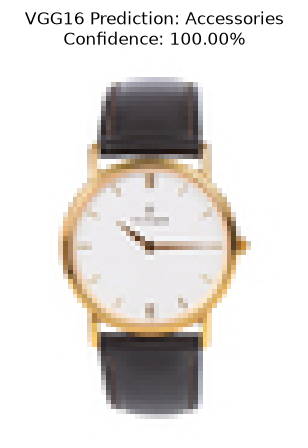

In [87]:
image = Image.open(sample_image_path).convert("RGB")

plt.figure(figsize=(5, 5))

plt.imshow(image)

plt.axis("off")

plt.title(
    f"VGG16 Prediction: {predicted_category}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()